In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
print("PyTorch Version:", torch.__version__)

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Selected Device:", device)

PyTorch Version: 2.7.1+cu118
CUDA Available: True
GPU Name: NVIDIA GeForce RTX 3050 A Laptop GPU
Selected Device: cuda


In [3]:
if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    total_memory = torch.cuda.get_device_properties(0).total_memory

    print("Total GPU Memory:",
          round(total_memory / (1024**3), 2), "GB")

    print("Allocated Memory:",
          round(torch.cuda.memory_allocated(0) / (1024**3), 2), "GB")

    print("Reserved Memory:",
          round(torch.cuda.memory_reserved(0) / (1024**3), 2), "GB")

GPU: NVIDIA GeForce RTX 3050 A Laptop GPU
Total GPU Memory: 4.0 GB
Allocated Memory: 0.0 GB
Reserved Memory: 0.0 GB


In [4]:
import torch

device = torch.device("cuda")

a = torch.randn(1000, 1000, device=device)
b = torch.randn(1000, 1000, device=device)

c = torch.matmul(a, b)

print("Computation device:", c.device)
print("Output shape:", c.shape)

print("Allocated GPU memory:",
      torch.cuda.memory_allocated() / 1024**2, "MB")

Computation device: cuda:0
Output shape: torch.Size([1000, 1000])
Allocated GPU memory: 20.0 MB


In [6]:
from pathlib import Path

DATASET_PATH = Path(r"C:\Users\simra\Downloads\archive (19)\PlantVillage")

print("Dataset exists:", DATASET_PATH.exists())

if DATASET_PATH.exists():
    print("\nFolders:")
    for folder in DATASET_PATH.iterdir():
        if folder.is_dir():
            print(folder.name)

Dataset exists: True

Folders:
train
val


In [7]:
image_extensions = {".jpg", ".jpeg", ".png"}

class_counts = {}

for folder in DATASET_PATH.iterdir():
    if folder.is_dir():
        count = sum(
            1 for file in folder.iterdir()
            if file.suffix.lower() in image_extensions
        )
        if count > 0:
            class_counts[folder.name] = count

print("Number of classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

Number of classes: 0
Total images: 0


In [11]:
image_extensions = {".jpg", ".jpeg", ".png"}

all_images = [
    file for file in DATASET_PATH.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("Total images found:", len(all_images))

for image in all_images[:10]:
    print(image)

Total images found: 54305
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\03354abb-aa1c-4f9d-a1ef-9f40505cd539___FREC_Scab 3355.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\0395b847-2c73-4674-826f-33a6afb5b4fe___FREC_Scab 3287.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\0a14783a-838a-4d4f-a671-ff98011714c6___FREC_Scab 3288.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\0b170906-9436-4c0d-84c1-c396ad9d909b___FREC_Scab 3101.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\0d3c0790-7833-470b-ac6e-94d0a3bf3e7c___FREC_Scab 2959.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage\val\Apple___Apple_scab\0e90fe4a-e8b6-4186-9429-a9fea180af9a___FREC_Scab 3391.JPG
C:\Users\simra\Downloads\archive (19)\PlantVillage

In [12]:
image_extensions = {".jpg", ".jpeg", ".png"}

for split in ["train", "val", "test"]:
    split_path = DATASET_PATH / split

    if split_path.exists():
        images = [
            file for file in split_path.rglob("*")
            if file.is_file() and file.suffix.lower() in image_extensions
        ]

        classes = [
            folder for folder in split_path.iterdir()
            if folder.is_dir()
        ]

        print(f"\n{split.upper()}")
        print("Number of classes:", len(classes))
        print("Number of images:", len(images))


TRAIN
Number of classes: 38
Number of images: 43444

VAL
Number of classes: 38
Number of images: 10861


In [13]:
TRAIN_DIR = DATASET_PATH / "train"
VAL_DIR = DATASET_PATH / "val"

print("Training directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)

Training directory: C:\Users\simra\Downloads\archive (19)\PlantVillage\train
Validation directory: C:\Users\simra\Downloads\archive (19)\PlantVillage\val


In [14]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [15]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=val_transform
)

class_names = train_dataset.classes
num_classes = len(class_names)

assert train_dataset.class_to_idx == val_dataset.class_to_idx

print("Number of classes:", num_classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\nClass names:")
for name in class_names:
    print(name)

Number of classes: 38
Training images: 43444
Validation images: 10861

Class names:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Y

In [16]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 2716
Validation batches: 679


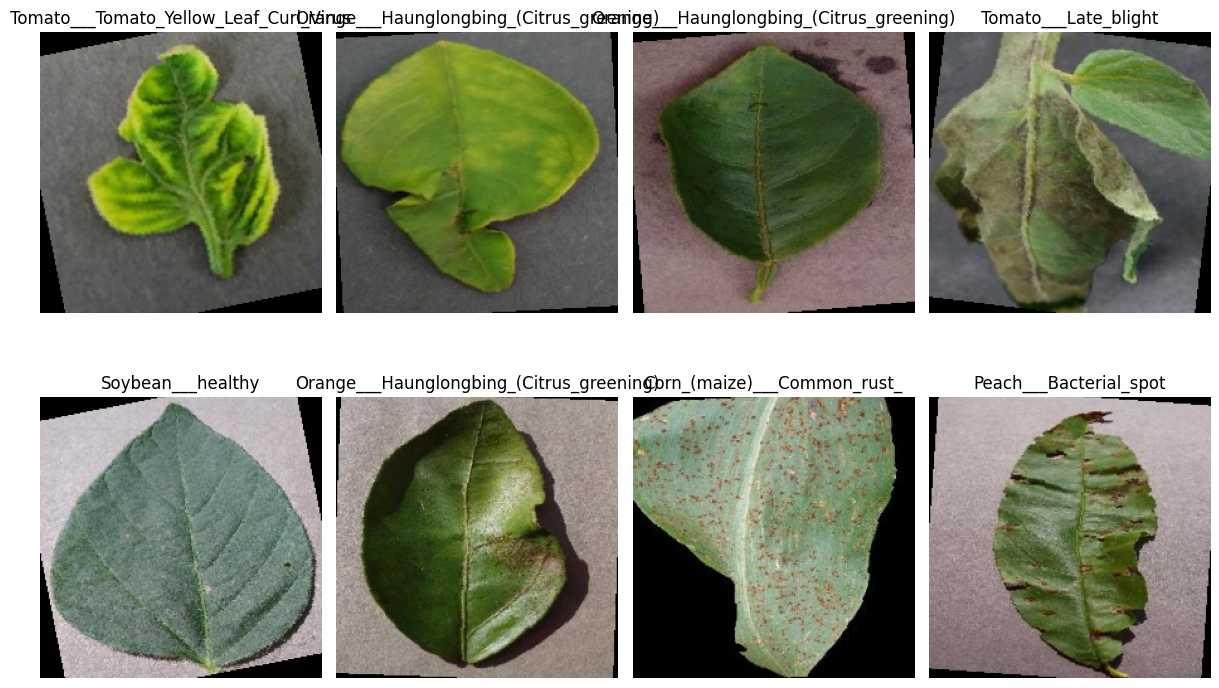

In [17]:
images, labels = next(iter(train_loader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(12, 8))

for i in range(8):
    image = images[i] * std + mean
    image = image.permute(1, 2, 0).clamp(0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:


class CropDiseaseCNN(nn.Module):

    def __init__(self, num_classes):
        super(CropDiseaseCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CropDiseaseCNN(num_classes=num_classes)

model = model.to(device)

print(model)

print("\nModel device:", next(model.parameters()).device)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_parameters)

CropDiseaseCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=

In [20]:
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Expected output:", (BATCH_SIZE, num_classes))

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 38])
Expected output: (16, 38)


In [21]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [22]:
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("Mixed precision enabled:", device.type == "cuda")

Mixed precision enabled: True


In [23]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [24]:
def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [25]:
EPOCHS = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0

os.makedirs("models", exist_ok=True)

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc:.2f}%")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "num_classes": num_classes,
            "image_size": IMAGE_SIZE,
            "best_val_accuracy": best_val_accuracy
        }, "models/best_crop_model.pth")

        print("Best model saved!")


Epoch [1/20]
Training Loss: 1.4884
Training Accuracy: 56.34%
Validation Loss: 0.8143
Validation Accuracy: 75.78%
Best model saved!

Epoch [2/20]
Training Loss: 0.8847
Training Accuracy: 72.45%
Validation Loss: 0.4331
Validation Accuracy: 86.36%
Best model saved!

Epoch [3/20]
Training Loss: 0.6894
Training Accuracy: 78.39%
Validation Loss: 0.3704
Validation Accuracy: 88.15%
Best model saved!

Epoch [4/20]
Training Loss: 0.5574
Training Accuracy: 82.13%
Validation Loss: 0.2738
Validation Accuracy: 91.57%
Best model saved!

Epoch [5/20]
Training Loss: 0.4696
Training Accuracy: 84.81%
Validation Loss: 0.2329
Validation Accuracy: 92.64%
Best model saved!

Epoch [6/20]
Training Loss: 0.4105
Training Accuracy: 86.76%
Validation Loss: 0.1694
Validation Accuracy: 94.56%
Best model saved!

Epoch [7/20]
Training Loss: 0.3593
Training Accuracy: 88.41%
Validation Loss: 0.1900
Validation Accuracy: 93.84%

Epoch [8/20]
Training Loss: 0.3298
Training Accuracy: 89.42%
Validation Loss: 0.1888
Validati

In [1]:
plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid()
plt.show()

NameError: name 'plt' is not defined

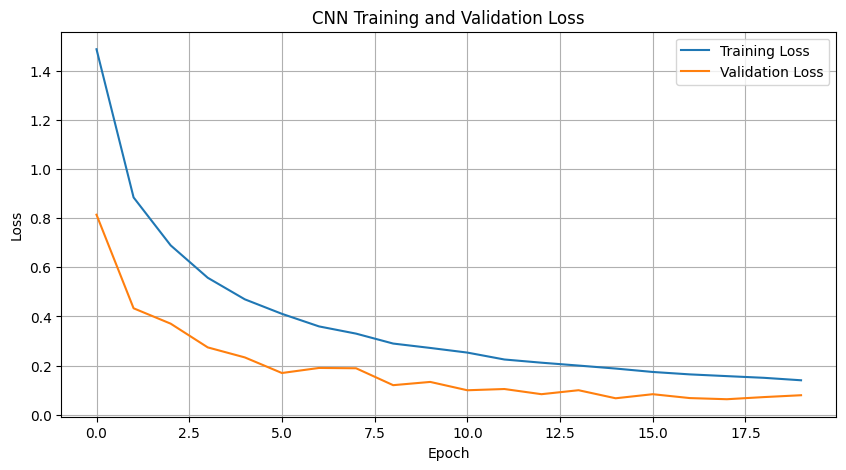

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid()
plt.show()

In [4]:
%cd ultralytics

[WinError 2] The system cannot find the file specified: 'ultralytics'
C:\Users\simra


In [6]:
import os
print(os.getcwd())

C:\Users\simra


In [7]:
import os

print(os.listdir(r"C:\Users\simra"))

['-1.14-windows.xml', '.arduinoIDE', '.bash_history', '.cache', '.claude', '.claude.json', '.codeium', '.codex', '.copilot', '.ghcp-appmod', '.ghcp-appmod-java', '.git-for-windows-updater', '.gitconfig', '.gitignore', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.matplotlib', '.mirror2_notes.json', '.node_repl_history', '.npmrc', '.nvidia-omniverse', '.pm2', '.python_history', '.redhat', '.streamlit', '.viminfo', '.VirtualBox', '.vscode', '.vscode-shared', '.windsurf', 'AppData', 'Application Data', 'chatbot', 'class student{.java', 'code.c', 'Contacts', 'Cookies', 'crop_health_analysis', 'CrossDevice', 'delete', 'Desktop', 'Documents', 'Downloads', 'Ecommerce', 'Ecommerce.ipynb', 'Favorites', 'filehandling.c', 'firstgitrepository', 'github', 'hello.py', 'index.html', 'java', 'linear_regression.ipynb', 'Links', 'Local Settings', 'Machine_learning', 'ML-project', 'ML_based_Ecommerce', 'models', 'Music', 'My Documents', 'mysql', 'NetHood', 'new.html', 'NTUSER.DAT', 'ntuser.

In [5]:
print("Number of classes:", checkpoint["num_classes"])

print("Class names:", checkpoint["class_names"])

print("Image size:", checkpoint["image_size"])

print("Best validation accuracy:",
      checkpoint["best_val_accuracy"])

Number of classes: 38
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotte